# A3 -- APU Air Compressor Anomaly Detection

**Asset**: MetroPT-3 dataset (Porto metro fleet, Feb--Aug 2020, ~1.5M rows at 1 Hz)  
**ML Paradigm**: Unsupervised anomaly detection + Remaining Useful Life (RUL) estimation  
**Objective**: Detect air-leak anomalies without labeled training data; validate against 4 documented failure windows  

**Known Failure Windows** (from the MetroPT-3 paper):  
1. 2020-04-18 (air leak, ~1 day)  
2. 2020-05-29 to 2020-05-30 (air leak, ~1 day)  
3. 2020-06-05 to 2020-06-07 (air leak, ~2 days)  
4. 2020-07-15 (air leak, ~1 day)  

---

## 1. Environment Setup and Data Loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from pathlib import Path
from datetime import datetime, timedelta

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
import joblib

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (14, 6)

REPO_ROOT = Path("..").resolve()
DATASET_PATH = REPO_ROOT / "metropt+3+dataset" / "MetroPT3(AirCompressor).csv"
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)

print(f"Dataset: {DATASET_PATH}")
print(f"File size: {DATASET_PATH.stat().st_size / 1e6:.1f} MB")
print(f"Model output: {MODEL_DIR.resolve()}")

Dataset: C:\Users\MSI\Documents\jesa\metropt+3+dataset\MetroPT3(AirCompressor).csv
File size: 218.3 MB
Model output: C:\Users\MSI\Documents\jesa\notebooks\models


In [2]:
# Define the known failure windows for validation
FAILURE_WINDOWS = [
    ("2020-04-18 00:00:00", "2020-04-18 23:59:59"),
    ("2020-05-29 00:00:00", "2020-05-30 23:59:59"),
    ("2020-06-05 00:00:00", "2020-06-07 23:59:59"),
    ("2020-07-15 00:00:00", "2020-07-15 23:59:59"),
]

FAILURE_WINDOWS_DT = [
    (pd.Timestamp(s), pd.Timestamp(e)) for s, e in FAILURE_WINDOWS
]

def is_in_failure_window(ts):
    """Check if a timestamp falls within any known failure window."""
    for start, end in FAILURE_WINDOWS_DT:
        if start <= ts <= end:
            return True
    return False

print("Failure windows defined:")
for i, (s, e) in enumerate(FAILURE_WINDOWS_DT, 1):
    duration = (e - s).total_seconds() / 3600
    print(f"  [{i}] {s.date()} to {e.date()} ({duration:.0f} hours)")

Failure windows defined:
  [1] 2020-04-18 to 2020-04-18 (24 hours)
  [2] 2020-05-29 to 2020-05-30 (48 hours)
  [3] 2020-06-05 to 2020-06-07 (72 hours)
  [4] 2020-07-15 to 2020-07-15 (24 hours)


## 2. Data Loading and Initial Exploration

The dataset has ~15M rows. We load it in full but downsample to 1-minute resolution
for model training (aggregating 60 samples per minute). This reduces memory requirements
while preserving the temporal patterns relevant for anomaly detection.

In [3]:
# Load the full dataset
print("Loading dataset (this may take a moment)...")
df = pd.read_csv(DATASET_PATH, index_col=0, parse_dates=["timestamp"])
print(f"Raw shape: {df.shape}")
print(f"Date range: {df['timestamp'].min()} to {df['timestamp'].max()}")
print(f"Columns: {list(df.columns)}")
df.head()

Loading dataset (this may take a moment)...


Raw shape: (1516948, 16)
Date range: 2020-02-01 00:00:00 to 2020-09-01 03:59:50
Columns: ['timestamp', 'TP2', 'TP3', 'H1', 'DV_pressure', 'Reservoirs', 'Oil_temperature', 'Motor_current', 'COMP', 'DV_eletric', 'Towers', 'MPG', 'LPS', 'Pressure_switch', 'Oil_level', 'Caudal_impulses']


,timestamp,TP2,TP3,H1,DV_pressure,Reservoirs,Oil_temperature,Motor_current,COMP,DV_eletric,Towers,MPG,LPS,Pressure_switch,Oil_level,Caudal_impulses
0,2020-02-01 00:00:00,-0.012,9.358,9.340,-0.024,9.358,53.600,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
10,2020-02-01 00:00:10,-0.014,9.348,9.332,-0.022,9.348,53.675,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
20,2020-02-01 00:00:19,-0.012,9.338,9.322,-0.022,9.338,53.600,0.0425,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
30,2020-02-01 00:00:29,-0.012,9.328,9.312,-0.022,9.328,53.425,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0
40,2020-02-01 00:00:39,-0.012,9.318,9.302,-0.022,9.318,53.475,0.0400,1.0,0.0,1.0,1.0,0.0,1.0,1.0,1.0


In [4]:
# Define signal groups
ANALOG_COLS = ["TP2", "TP3", "H1", "DV_pressure", "Reservoirs",
               "Oil_temperature", "Motor_current"]
DIGITAL_COLS = ["COMP", "DV_eletric", "Towers", "MPG", "LPS",
                "Pressure_switch", "Oil_level", "Caudal_impulses"]

print("Analog signal statistics:")
print(df[ANALOG_COLS].describe().round(3))

Analog signal statistics:


               TP2          TP3           H1  DV_pressure   Reservoirs  \
count  1516948.000  1516948.000  1516948.000  1516948.000  1516948.000   
mean         1.368        8.985        7.568        0.056        8.985   
std          3.251        0.639        3.333        0.382        0.638   
min         -0.032        0.730       -0.036       -0.032        0.712   
25%         -0.014        8.492        8.254       -0.022        8.494   
50%         -0.012        8.960        8.784       -0.020        8.960   
75%         -0.010        9.492        9.374       -0.018        9.492   
max         10.676       10.302       10.288        9.844       10.300   

       Oil_temperature  Motor_current  
count      1516948.000    1516948.000  
mean            62.644          2.050  
std              6.516          2.302  
min             15.400          0.020  
25%             57.775          0.040  
50%             62.700          0.045  
75%             67.250          3.808  
max          

## 3. Preprocessing and Downsampling

Resample to 1-minute resolution:
- Analog signals: mean per minute
- Digital signals: mean per minute (duty cycle ratio)
- COMP duty cycle: fraction of time compressor was running per minute

In [5]:
# Set timestamp as index for resampling
df = df.set_index("timestamp")
df = df.sort_index()

# Remove duplicate timestamps if any
df = df[~df.index.duplicated(keep="first")]

# Resample to 1-minute resolution
df_1min = df.resample("1min").mean()

# Drop rows that are entirely NaN (gaps in recording)
df_1min = df_1min.dropna(how="all")

# Forward-fill remaining sparse NaNs (within short gaps)
df_1min = df_1min.ffill(limit=5)
df_1min = df_1min.dropna()

print(f"Resampled shape: {df_1min.shape}")
print(f"Date range: {df_1min.index.min()} to {df_1min.index.max()}")
print(f"Memory: {df_1min.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Free the raw dataframe from memory
del df

Resampled shape: (252720, 15)
Date range: 2020-02-01 00:00:00 to 2020-09-01 03:59:00
Memory: 32.3 MB


## 4. Feature Engineering

Compute rolling window features that capture the temporal dynamics of the compressor:
- 5-minute rolling statistics (mean, std, range) on analog signals
- 30-minute rolling statistics for longer-term trend detection
- COMP duty cycle (fraction of running time per window)

In [6]:
# Rolling window features on the 1-minute data
WINDOW_SHORT = 5   # 5-minute rolling window
WINDOW_LONG = 30   # 30-minute rolling window

feature_cols = []

for col in ANALOG_COLS:
    # Short window features
    df_1min[f"{col}_roll5_mean"] = df_1min[col].rolling(WINDOW_SHORT, min_periods=1).mean()
    df_1min[f"{col}_roll5_std"] = df_1min[col].rolling(WINDOW_SHORT, min_periods=1).std().fillna(0)

    # Long window features
    df_1min[f"{col}_roll30_mean"] = df_1min[col].rolling(WINDOW_LONG, min_periods=1).mean()
    df_1min[f"{col}_roll30_std"] = df_1min[col].rolling(WINDOW_LONG, min_periods=1).std().fillna(0)

    feature_cols.extend([
        f"{col}_roll5_mean", f"{col}_roll5_std",
        f"{col}_roll30_mean", f"{col}_roll30_std",
    ])

# COMP duty cycle (fraction of running time)
df_1min["COMP_duty_5min"] = df_1min["COMP"].rolling(WINDOW_SHORT, min_periods=1).mean()
df_1min["COMP_duty_30min"] = df_1min["COMP"].rolling(WINDOW_LONG, min_periods=1).mean()
feature_cols.extend(["COMP_duty_5min", "COMP_duty_30min"])

# Pressure differential features
df_1min["TP3_Reservoirs_diff"] = df_1min["TP3"] - df_1min["Reservoirs"]
df_1min["TP3_TP2_diff"] = df_1min["TP3"] - df_1min["TP2"]
feature_cols.extend(["TP3_Reservoirs_diff", "TP3_TP2_diff"])

# Drop initial rows where rolling windows are not fully populated
df_1min = df_1min.iloc[WINDOW_LONG:]

print(f"Feature matrix shape: {df_1min[feature_cols].shape}")
print(f"Number of engineered features: {len(feature_cols)}")
print(f"Date range after windowing: {df_1min.index.min()} to {df_1min.index.max()}")

Feature matrix shape: (252690, 32)
Number of engineered features: 32
Date range after windowing: 2020-02-01 00:30:00 to 2020-09-01 03:59:00


## 5. Ground-Truth Labeling and Train/Test Split

Labels are applied only for evaluation purposes. The models are trained exclusively
on data from a confirmed-healthy period (February 2020, before any documented failures).
This is the fundamental principle of unsupervised anomaly detection: train on normal
behavior, detect deviations.

In [7]:
# Create ground-truth label column (for evaluation only, not for training)
df_1min["is_anomaly"] = df_1min.index.map(
    lambda ts: 1 if any(s <= ts <= e for s, e in FAILURE_WINDOWS_DT) else 0
)

n_anomaly = df_1min["is_anomaly"].sum()
n_total = len(df_1min)
print(f"Total samples: {n_total}")
print(f"Anomaly samples: {n_anomaly} ({n_anomaly/n_total*100:.2f}%)")
print(f"Normal samples:  {n_total - n_anomaly} ({(n_total-n_anomaly)/n_total*100:.2f}%)")

# Define the healthy training period: February 2020 (well before any failures)
HEALTHY_START = "2020-02-01"
HEALTHY_END = "2020-03-31"

mask_healthy = (df_1min.index >= HEALTHY_START) & (df_1min.index <= HEALTHY_END)
X_healthy = df_1min.loc[mask_healthy, feature_cols].values

# Full dataset for scoring
X_all = df_1min[feature_cols].values

print(f"\nHealthy training period: {HEALTHY_START} to {HEALTHY_END}")
print(f"Healthy training samples: {X_healthy.shape[0]}")

# Verify no anomaly labels in training period
train_anomalies = df_1min.loc[mask_healthy, "is_anomaly"].sum()
print(f"Anomaly labels in training period: {train_anomalies} (should be 0)")

Total samples: 252690
Anomaly samples: 8993 (3.56%)
Normal samples:  243697 (96.44%)

Healthy training period: 2020-02-01 to 2020-03-31
Healthy training samples: 72169
Anomaly labels in training period: 0 (should be 0)


In [8]:
# Scale features (fit on healthy data only)
scaler = StandardScaler()
X_healthy_scaled = scaler.fit_transform(X_healthy)
X_all_scaled = scaler.transform(X_all)

print(f"Scaler fitted on {X_healthy_scaled.shape[0]} healthy samples")
print(f"Full dataset scaled: {X_all_scaled.shape}")

Scaler fitted on 72169 healthy samples
Full dataset scaled: (252690, 32)


## 6. Raw Signal Exploration with Failure Windows

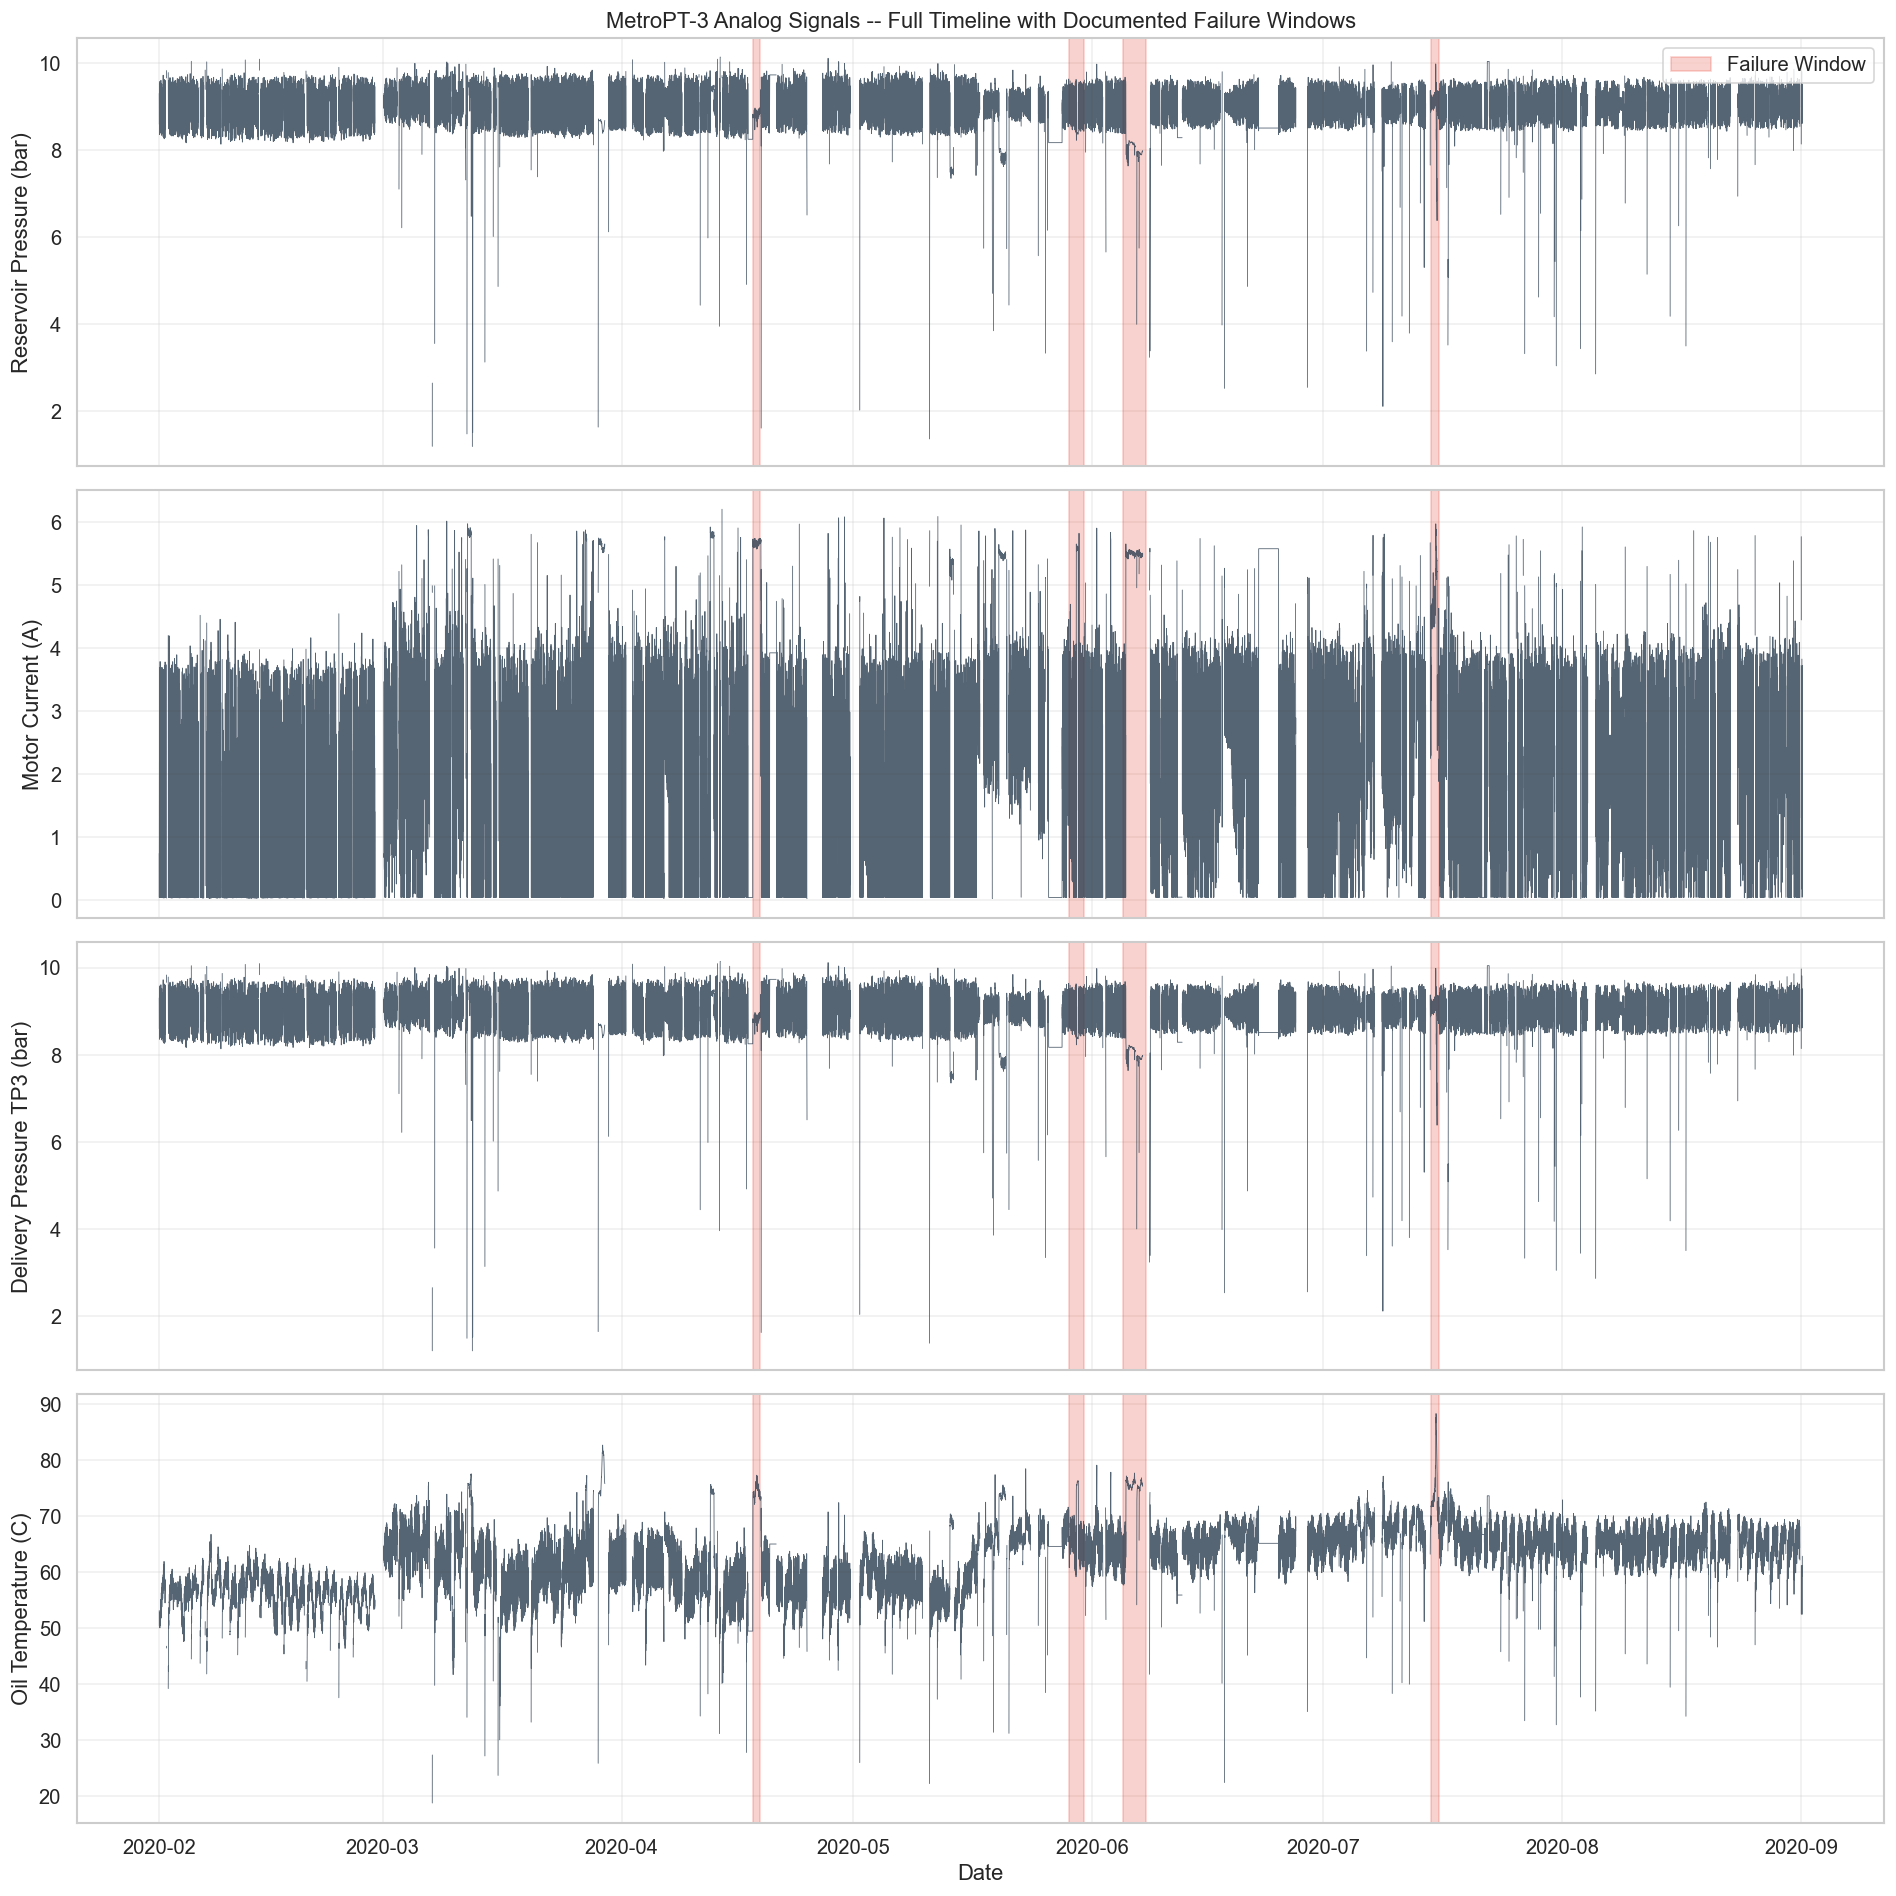

In [9]:
# Plot key analog signals across the full timeline with failure windows highlighted
fig, axes = plt.subplots(4, 1, figsize=(16, 16), sharex=True)

plot_cols = ["Reservoirs", "Motor_current", "TP3", "Oil_temperature"]
plot_labels = ["Reservoir Pressure (bar)", "Motor Current (A)",
               "Delivery Pressure TP3 (bar)", "Oil Temperature (C)"]

for ax, col, label in zip(axes, plot_cols, plot_labels):
    # Downsample further for plotting (every 10 minutes)
    plot_data = df_1min[col].resample("10min").mean()
    ax.plot(plot_data.index, plot_data.values, linewidth=0.5, color="#2c3e50", alpha=0.8)

    # Highlight failure windows
    for start, end in FAILURE_WINDOWS_DT:
        ax.axvspan(start, end, color="#e74c3c", alpha=0.25, label="Failure Window")

    ax.set_ylabel(label)
    ax.grid(True, alpha=0.3)

# Add legend to first axis (avoid duplicate labels)
handles, labels = axes[0].get_legend_handles_labels()
by_label = dict(zip(labels, handles))
axes[0].legend(by_label.values(), by_label.keys(), loc="upper right")

axes[0].set_title("MetroPT-3 Analog Signals -- Full Timeline with Documented Failure Windows")
axes[-1].set_xlabel("Date")
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
plt.tight_layout()
plt.savefig("models/a3_raw_signals_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Model 1 -- Isolation Forest

Isolation Forest detects anomalies by isolating observations through random partitioning.
Points that require fewer splits to isolate are considered more anomalous. We train
exclusively on the healthy period and score the entire dataset.

In [10]:
# Train Isolation Forest on healthy data
iso_forest = IsolationForest(
    n_estimators=200,
    max_samples=min(10000, X_healthy_scaled.shape[0]),
    contamination=0.01,  # Expected anomaly fraction in healthy data (noise)
    random_state=42,
    n_jobs=-1,
)

iso_forest.fit(X_healthy_scaled)
print("Isolation Forest trained on healthy data.")

# Score the entire dataset
# decision_function returns negative scores for anomalies
iso_scores_raw = iso_forest.decision_function(X_all_scaled)

# Convert to anomaly score (higher = more anomalous)
iso_anomaly_score = -iso_scores_raw

# Normalize to [0, 1] range
iso_anomaly_score = (iso_anomaly_score - iso_anomaly_score.min()) /                     (iso_anomaly_score.max() - iso_anomaly_score.min())

df_1min["iso_score"] = iso_anomaly_score

print(f"Score range: [{iso_anomaly_score.min():.4f}, {iso_anomaly_score.max():.4f}]")
print(f"Healthy period mean score: {df_1min.loc[mask_healthy, 'iso_score'].mean():.4f}")
print(f"Overall mean score: {iso_anomaly_score.mean():.4f}")

Isolation Forest trained on healthy data.


Score range: [0.0000, 1.0000]
Healthy period mean score: 0.1215
Overall mean score: 0.1618


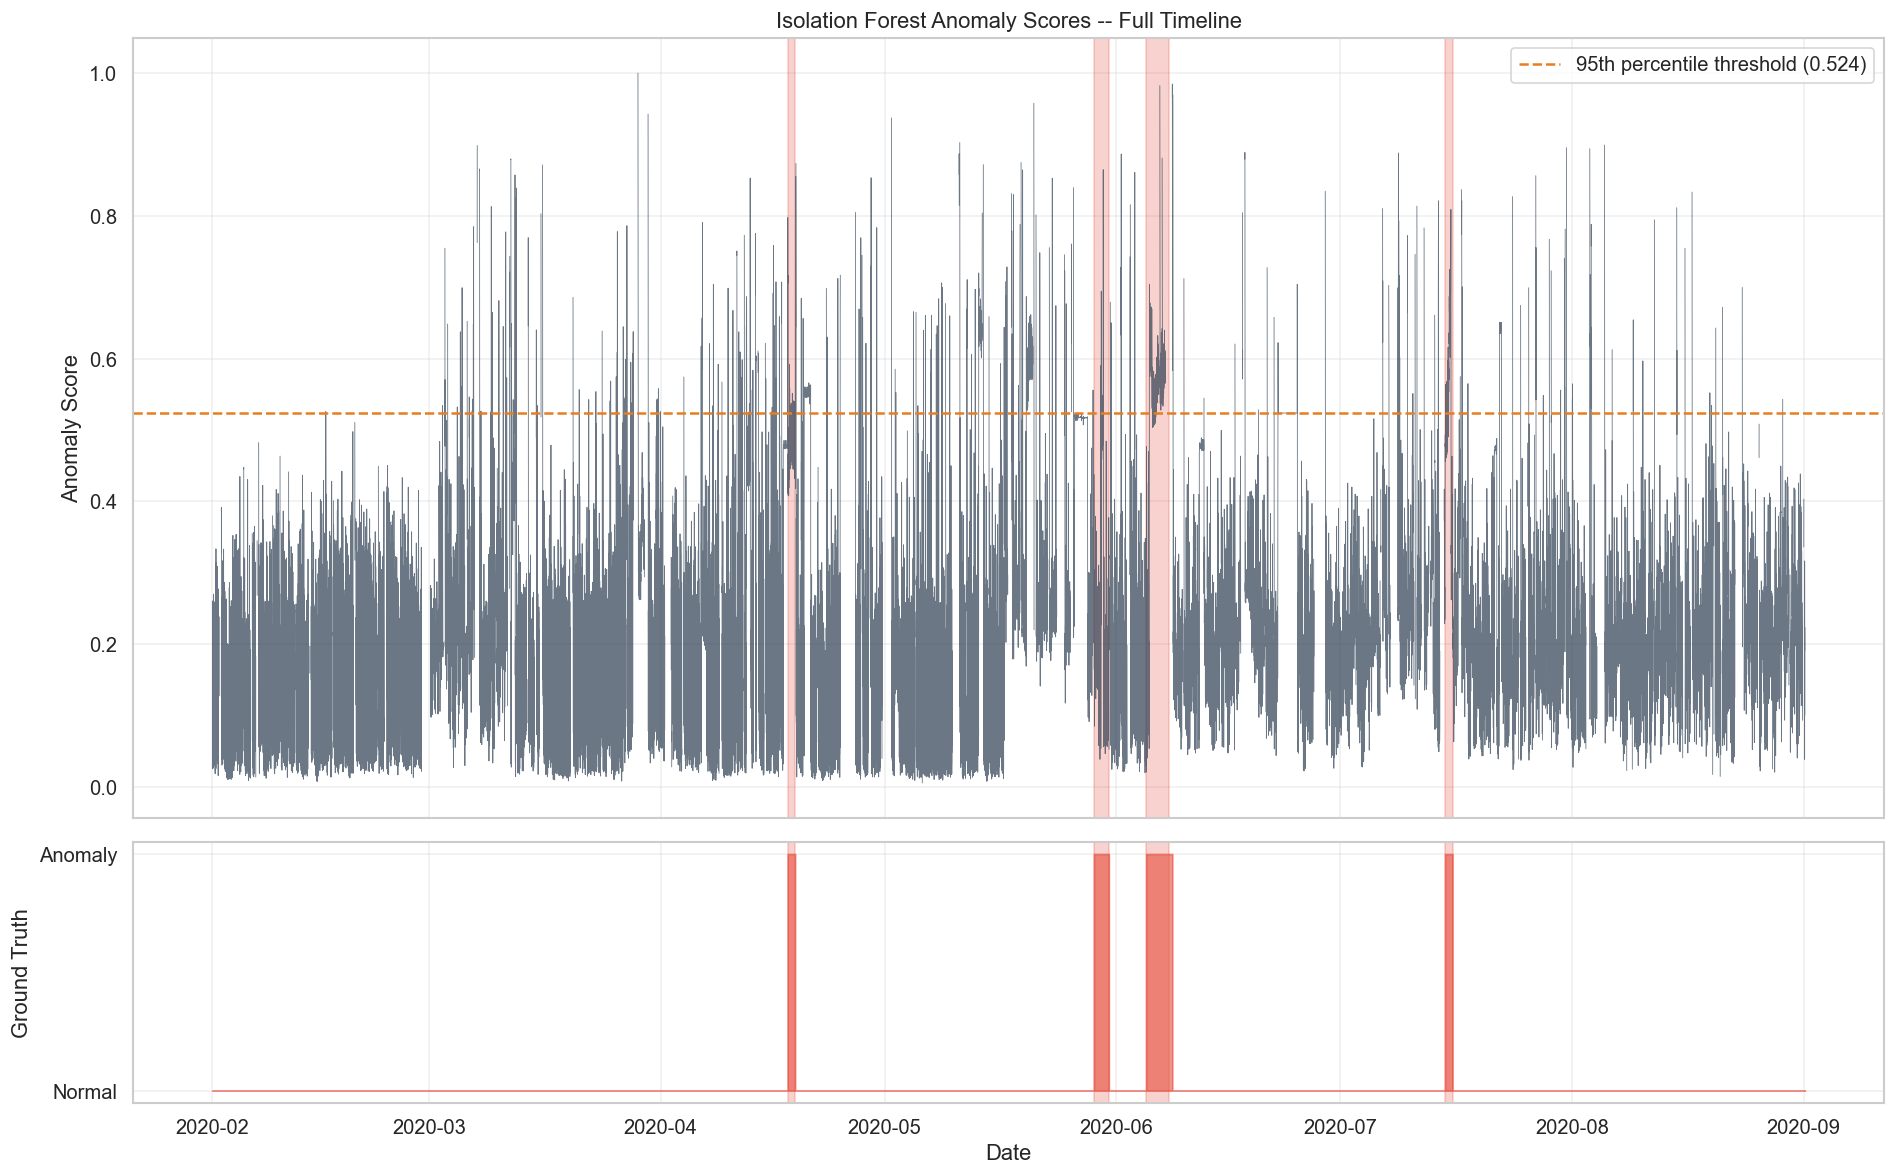

In [11]:
# Plot Isolation Forest anomaly scores across time
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

# Anomaly scores
plot_scores = df_1min["iso_score"].resample("10min").max()
axes[0].plot(plot_scores.index, plot_scores.values, linewidth=0.5, color="#2c3e50", alpha=0.7)
axes[0].set_ylabel("Anomaly Score")
axes[0].set_title("Isolation Forest Anomaly Scores -- Full Timeline")

# Highlight failure windows
for start, end in FAILURE_WINDOWS_DT:
    axes[0].axvspan(start, end, color="#e74c3c", alpha=0.25)
    axes[1].axvspan(start, end, color="#e74c3c", alpha=0.25)

# Threshold line
threshold_iso = np.percentile(iso_anomaly_score, 95)
axes[0].axhline(y=threshold_iso, color="#e67e22", linestyle="--", linewidth=1.5,
                label=f"95th percentile threshold ({threshold_iso:.3f})")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

# Ground truth
axes[1].fill_between(df_1min.index, 0, df_1min["is_anomaly"],
                      color="#e74c3c", alpha=0.6, step="post")
axes[1].set_ylabel("Ground Truth")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Normal", "Anomaly"])
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("models/a3_isolation_forest_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Model 2 -- Autoencoder (Reconstruction Error)

A feed-forward autoencoder learns to compress and reconstruct normal operating patterns.
During inference, anomalous patterns produce higher reconstruction errors because the
model has never seen them during training. We use a dense autoencoder here for
reliability and speed; an LSTM variant can be added for sequence-aware detection.

In [12]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# Build a PyTorch LSTM Autoencoder
# This inherently captures the temporal sequences of the air pressure data
class LSTMAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden_dim=16):
        super().__init__()
        self.encoder = nn.LSTM(input_dim, hidden_dim, batch_first=True)
        self.decoder = nn.LSTM(hidden_dim, input_dim, batch_first=True)
        
    def forward(self, x):
        # Encoder
        _, (hidden, _) = self.encoder(x)
        # Repeat hidden state for decoder input
        seq_len = x.shape[1]
        hidden_rep = hidden[-1].unsqueeze(1).repeat(1, seq_len, 1)
        # Decoder
        out, _ = self.decoder(hidden_rep)
        return out

SEQ_LEN = 10
def create_sequences(X):
    seqs = []
    for i in range(len(X) - SEQ_LEN + 1):
        seqs.append(X[i:i+SEQ_LEN])
    return np.array(seqs)

print("Preparing sequences for LSTM...")
X_healthy_seq = create_sequences(X_healthy_scaled)
X_all_seq = create_sequences(X_all_scaled)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training LSTM Autoencoder on {device}...")

autoencoder = LSTMAutoencoder(input_dim=X_healthy_scaled.shape[1], hidden_dim=64).to(device)
optimizer = torch.optim.Adam(autoencoder.parameters(), lr=0.005)
criterion = nn.MSELoss()

# Train
train_tensor = torch.FloatTensor(X_healthy_seq).to(device)
dataset = TensorDataset(train_tensor, train_tensor)
loader = DataLoader(dataset, batch_size=512, shuffle=True)

autoencoder.train()
epochs = 40
for epoch in range(epochs):
    epoch_loss = 0
    for batch_x, _ in loader:
        optimizer.zero_grad()
        output = autoencoder(batch_x)
        loss = criterion(output, batch_x)
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss/len(loader):.6f}")

print("Autoencoder trained.")

# Compute reconstruction error on all data
autoencoder.eval()
with torch.no_grad():
    all_tensor = torch.FloatTensor(X_all_seq).to(device)
    # Process in batches to avoid OOM
    batch_size = 1024
    reconstructed = []
    for i in range(0, len(all_tensor), batch_size):
        batch = all_tensor[i:i+batch_size]
        out = autoencoder(batch)
        reconstructed.append(out.cpu().numpy())
    X_reconstructed = np.vstack(reconstructed)

# Reconstruction error (MSE per sequence)
reconstruction_error = np.mean((X_all_seq - X_reconstructed) ** 2, axis=(1, 2))

# Pad the first (SEQ_LEN-1) rows with zeros to align indices with df_1min
pad = np.zeros(SEQ_LEN - 1)
reconstruction_error = np.concatenate([pad, reconstruction_error])

# Normalize to [0, 1]
ae_anomaly_score = (reconstruction_error - reconstruction_error.min()) /                    (reconstruction_error.max() - reconstruction_error.min())

df_1min["ae_score"] = ae_anomaly_score

print(f"\nReconstruction error range: [{reconstruction_error.min():.6f}, {reconstruction_error.max():.6f}]")
print(f"Healthy period mean error: {df_1min.loc[mask_healthy, 'ae_score'].mean():.4f}")
print(f"Overall mean error: {ae_anomaly_score.mean():.4f}")

Preparing sequences for LSTM...


Training LSTM Autoencoder on cpu...


Epoch 5/40, Loss: 0.383276


Epoch 10/40, Loss: 0.375467


Epoch 15/40, Loss: 0.372377


...

Epoch 25/40, Loss: 0.369820


Epoch 30/40, Loss: 0.368725


Epoch 35/40, Loss: 0.367701


Epoch 40/40, Loss: 0.367258
Autoencoder trained.



Reconstruction error range: [0.000000, 48.282504]
Healthy period mean error: 0.0076
Overall mean error: 0.0201


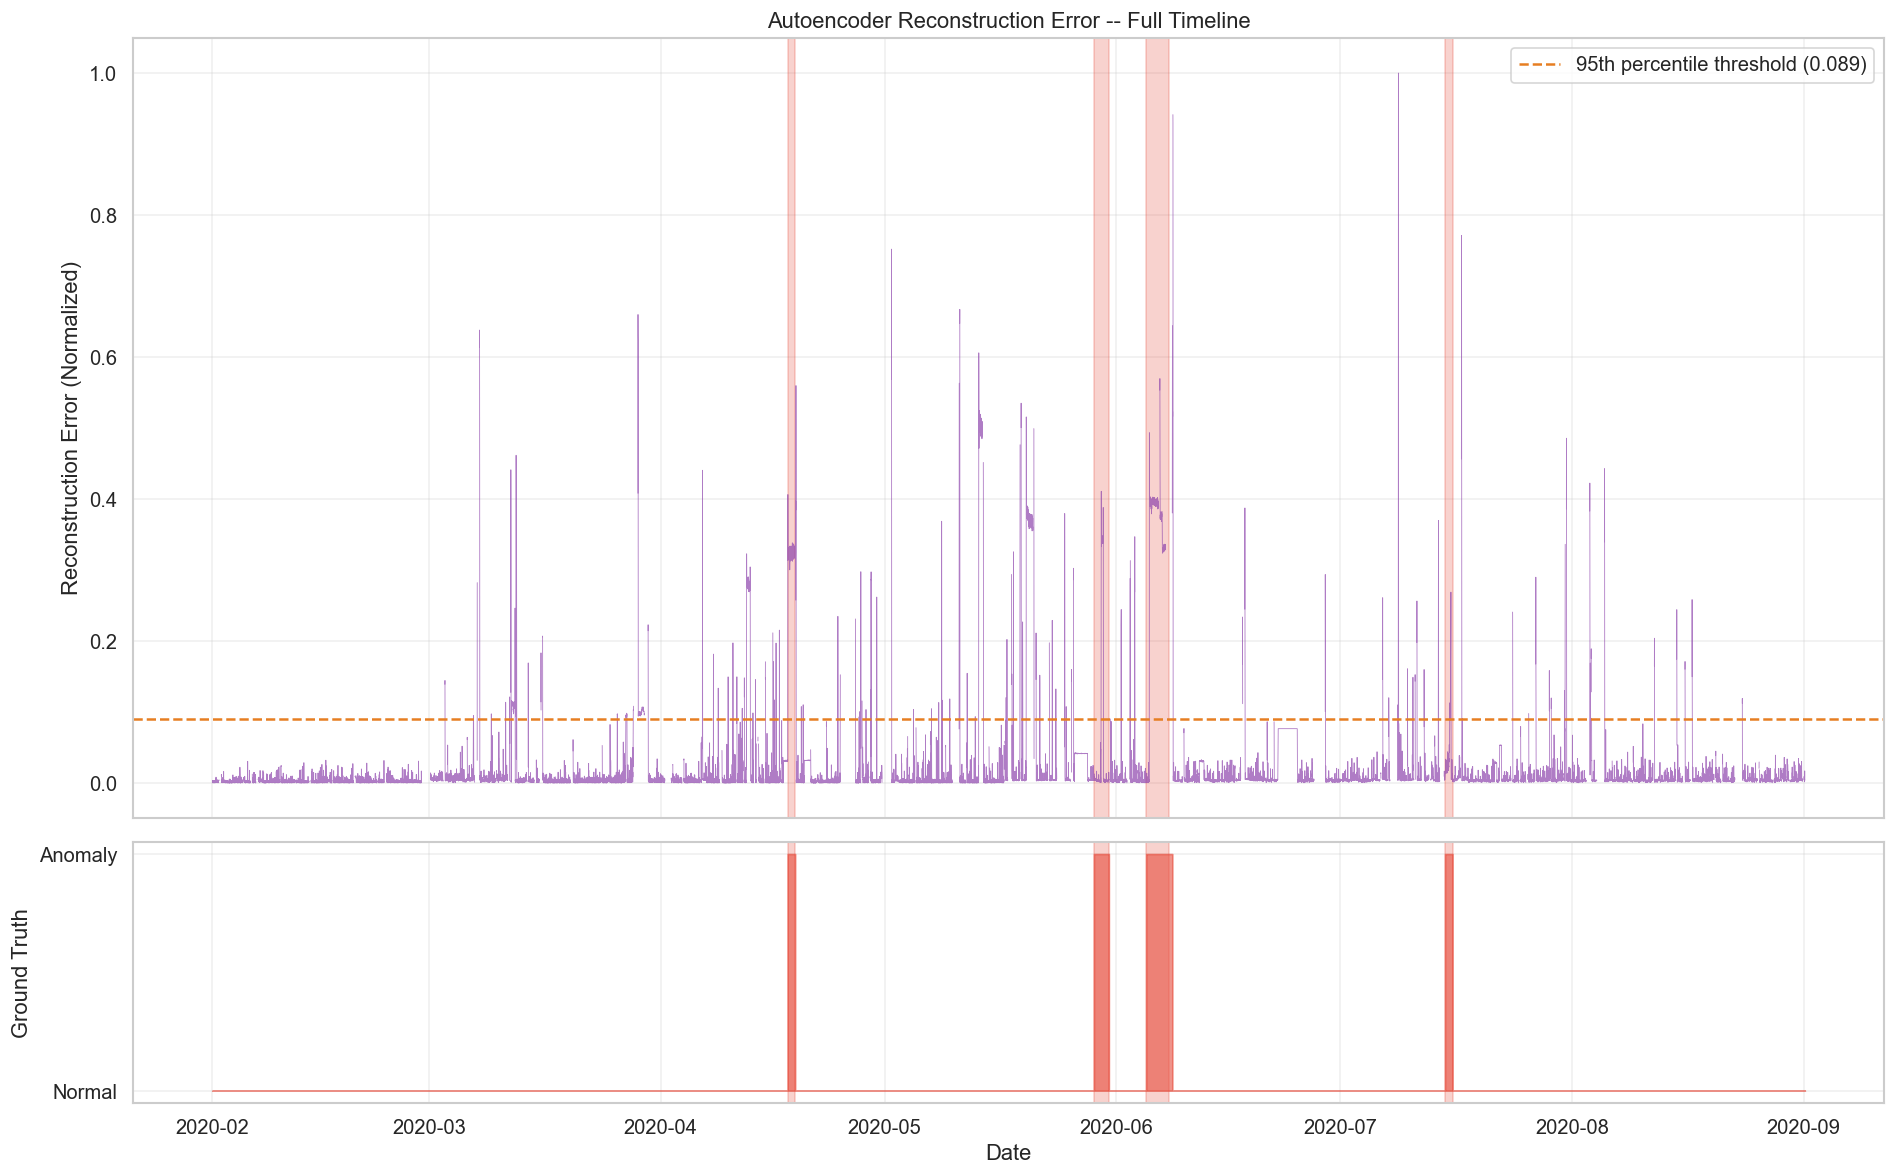

In [13]:
# Plot Autoencoder anomaly scores across time
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

plot_scores = df_1min["ae_score"].resample("10min").max()
axes[0].plot(plot_scores.index, plot_scores.values, linewidth=0.5, color="#8e44ad", alpha=0.7)
axes[0].set_ylabel("Reconstruction Error (Normalized)")
axes[0].set_title("Autoencoder Reconstruction Error -- Full Timeline")

for start, end in FAILURE_WINDOWS_DT:
    axes[0].axvspan(start, end, color="#e74c3c", alpha=0.25)
    axes[1].axvspan(start, end, color="#e74c3c", alpha=0.25)

threshold_ae = np.percentile(ae_anomaly_score, 95)
axes[0].axhline(y=threshold_ae, color="#e67e22", linestyle="--", linewidth=1.5,
                label=f"95th percentile threshold ({threshold_ae:.3f})")
axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(df_1min.index, 0, df_1min["is_anomaly"],
                      color="#e74c3c", alpha=0.6, step="post")
axes[1].set_ylabel("Ground Truth")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Normal", "Anomaly"])
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("models/a3_autoencoder_scores.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Model Comparison and Threshold Analysis

In [14]:
# Evaluate both models at multiple threshold percentiles
def evaluate_anomaly_detector(scores, ground_truth, threshold_percentile):
    """Evaluate at a given percentile threshold."""
    threshold = np.percentile(scores, threshold_percentile)
    predictions = (scores >= threshold).astype(int)
    prec = precision_score(ground_truth, predictions, zero_division=0)
    rec = recall_score(ground_truth, predictions, zero_division=0)
    f1 = f1_score(ground_truth, predictions, zero_division=0)
    return prec, rec, f1, threshold

y_true = df_1min["is_anomaly"].values

# Test at multiple thresholds
percentiles = [90, 92, 94, 95, 96, 97, 98, 99]

print(f"{'Percentile':>10s} | {'Iso Forest':>30s} | {'Autoencoder':>30s}")
print(f"{'':>10s} | {'Prec':>8s} {'Rec':>8s} {'F1':>8s} | {'Prec':>8s} {'Rec':>8s} {'F1':>8s}")
print("-" * 80)

iso_results = []
ae_results = []

for pct in percentiles:
    p_i, r_i, f1_i, _ = evaluate_anomaly_detector(iso_anomaly_score, y_true, pct)
    p_a, r_a, f1_a, _ = evaluate_anomaly_detector(ae_anomaly_score, y_true, pct)
    iso_results.append((pct, p_i, r_i, f1_i))
    ae_results.append((pct, p_a, r_a, f1_a))
    print(f"{pct:>10d} | {p_i:>8.3f} {r_i:>8.3f} {f1_i:>8.3f} | {p_a:>8.3f} {r_a:>8.3f} {f1_a:>8.3f}")

Percentile |                     Iso Forest |                    Autoencoder
           |     Prec      Rec       F1 |     Prec      Rec       F1
--------------------------------------------------------------------------------
        90 |    0.233    0.655    0.344 |    0.206    0.580    0.304
        92 |    0.222    0.500    0.308 |    0.251    0.564    0.347


        94 |    0.204    0.344    0.256 |    0.297    0.553    0.387
        95 |    0.217    0.324    0.260 |    0.392    0.550    0.457
        96 |    0.217    0.324    0.260 |    0.478    0.537    0.505


        97 |    0.263    0.223    0.241 |    0.617    0.520    0.565
        98 |    0.201    0.113    0.144 |    0.505    0.284    0.363
        99 |    0.163    0.046    0.072 |    0.543    0.153    0.238


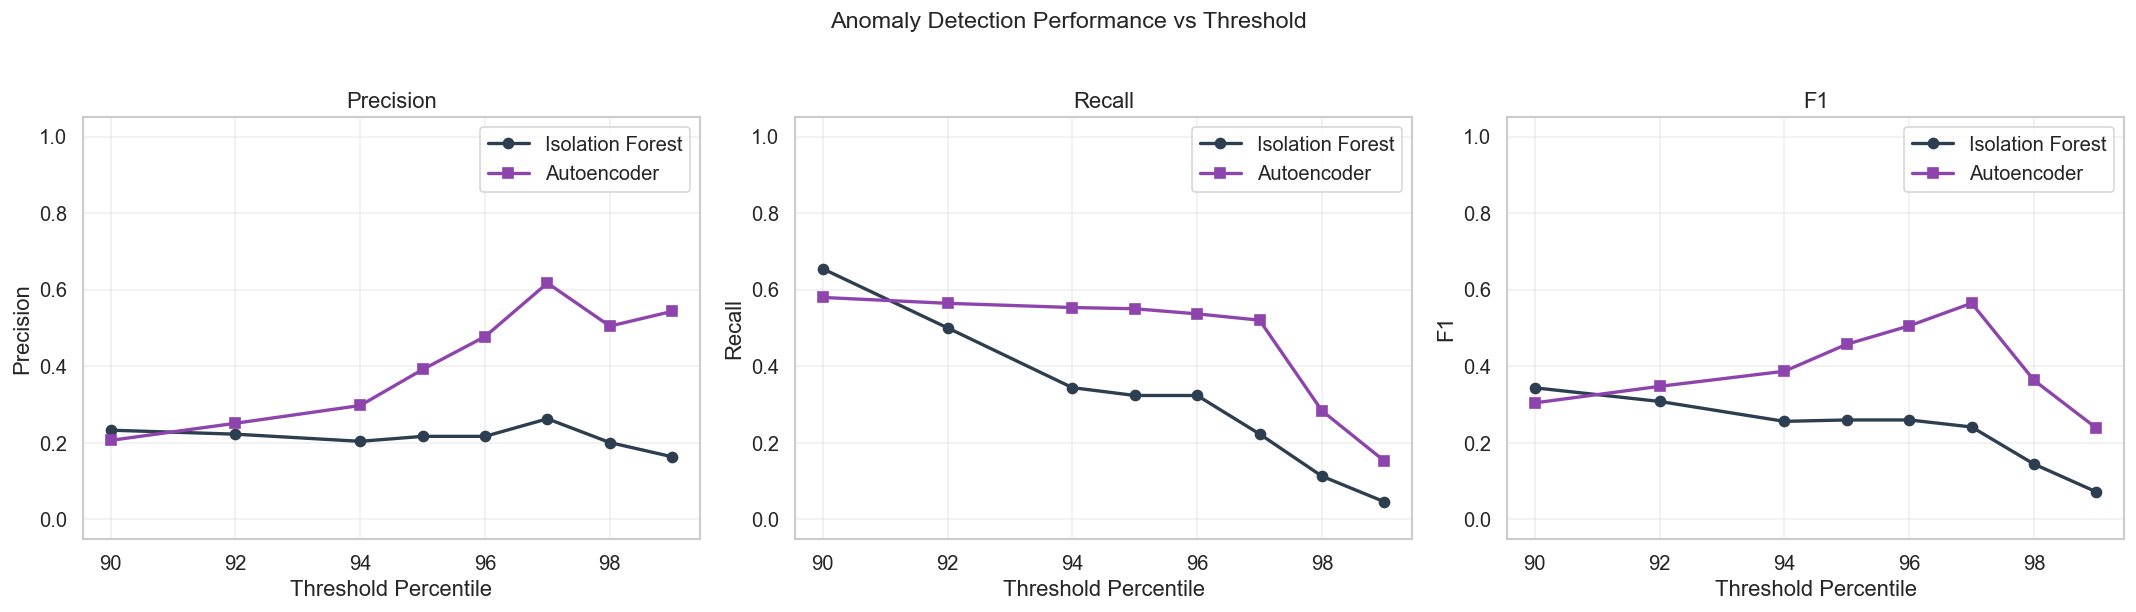

In [15]:
# Plot F1 scores vs threshold percentile for both models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for metric_idx, metric_name in enumerate(["Precision", "Recall", "F1"]):
    iso_vals = [r[metric_idx + 1] for r in iso_results]
    ae_vals = [r[metric_idx + 1] for r in ae_results]

    axes[metric_idx].plot(percentiles, iso_vals, "o-", color="#2c3e50",
                          linewidth=2, markersize=6, label="Isolation Forest")
    axes[metric_idx].plot(percentiles, ae_vals, "s-", color="#8e44ad",
                          linewidth=2, markersize=6, label="Autoencoder")
    axes[metric_idx].set_xlabel("Threshold Percentile")
    axes[metric_idx].set_ylabel(metric_name)
    axes[metric_idx].set_title(metric_name)
    axes[metric_idx].legend()
    axes[metric_idx].grid(True, alpha=0.3)
    axes[metric_idx].set_ylim(-0.05, 1.05)

plt.suptitle("Anomaly Detection Performance vs Threshold", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("models/a3_model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Per-Failure-Window Detection Analysis

In [16]:
# Analyze each failure window individually
# Use the best threshold (95th percentile) for both models
best_pct = 95

threshold_iso = np.percentile(iso_anomaly_score, best_pct)
threshold_ae = np.percentile(ae_anomaly_score, best_pct)

print(f"Threshold (95th percentile):")
print(f"  Isolation Forest: {threshold_iso:.4f}")
print(f"  Autoencoder:      {threshold_ae:.4f}")
print()

for i, (start, end) in enumerate(FAILURE_WINDOWS_DT, 1):
    mask_window = (df_1min.index >= start) & (df_1min.index <= end)
    n_samples = mask_window.sum()
    
    if n_samples == 0:
        print(f"Window {i} ({start.date()} to {end.date()}): No data in this period")
        continue
    
    iso_detected = (df_1min.loc[mask_window, "iso_score"] >= threshold_iso).sum()
    ae_detected = (df_1min.loc[mask_window, "ae_score"] >= threshold_ae).sum()
    
    print(f"Window {i} ({start.date()} to {end.date()}):")
    print(f"  Samples in window:    {n_samples}")
    print(f"  Isolation Forest:     {iso_detected}/{n_samples} detected "
          f"({iso_detected/n_samples*100:.1f}%)")
    print(f"  Autoencoder:          {ae_detected}/{n_samples} detected "
          f"({ae_detected/n_samples*100:.1f}%)")
    print()

Threshold (95th percentile):
  Isolation Forest: 0.5237
  Autoencoder:      0.0894

Window 1 (2020-04-18 to 2020-04-18):
  Samples in window:    1436
  Isolation Forest:     68/1436 detected (4.7%)
  Autoencoder:          1415/1436 detected (98.5%)

Window 2 (2020-05-29 to 2020-05-30):
  Samples in window:    2661
  Isolation Forest:     95/2661 detected (3.6%)
  Autoencoder:          428/2661 detected (16.1%)

Window 3 (2020-06-05 to 2020-06-07):
  Samples in window:    3463
  Isolation Forest:     2270/3463 detected (65.6%)
  Autoencoder:          2871/3463 detected (82.9%)

Window 4 (2020-07-15 to 2020-07-15):
  Samples in window:    1433
  Isolation Forest:     477/1433 detected (33.3%)
  Autoencoder:          233/1433 detected (16.3%)



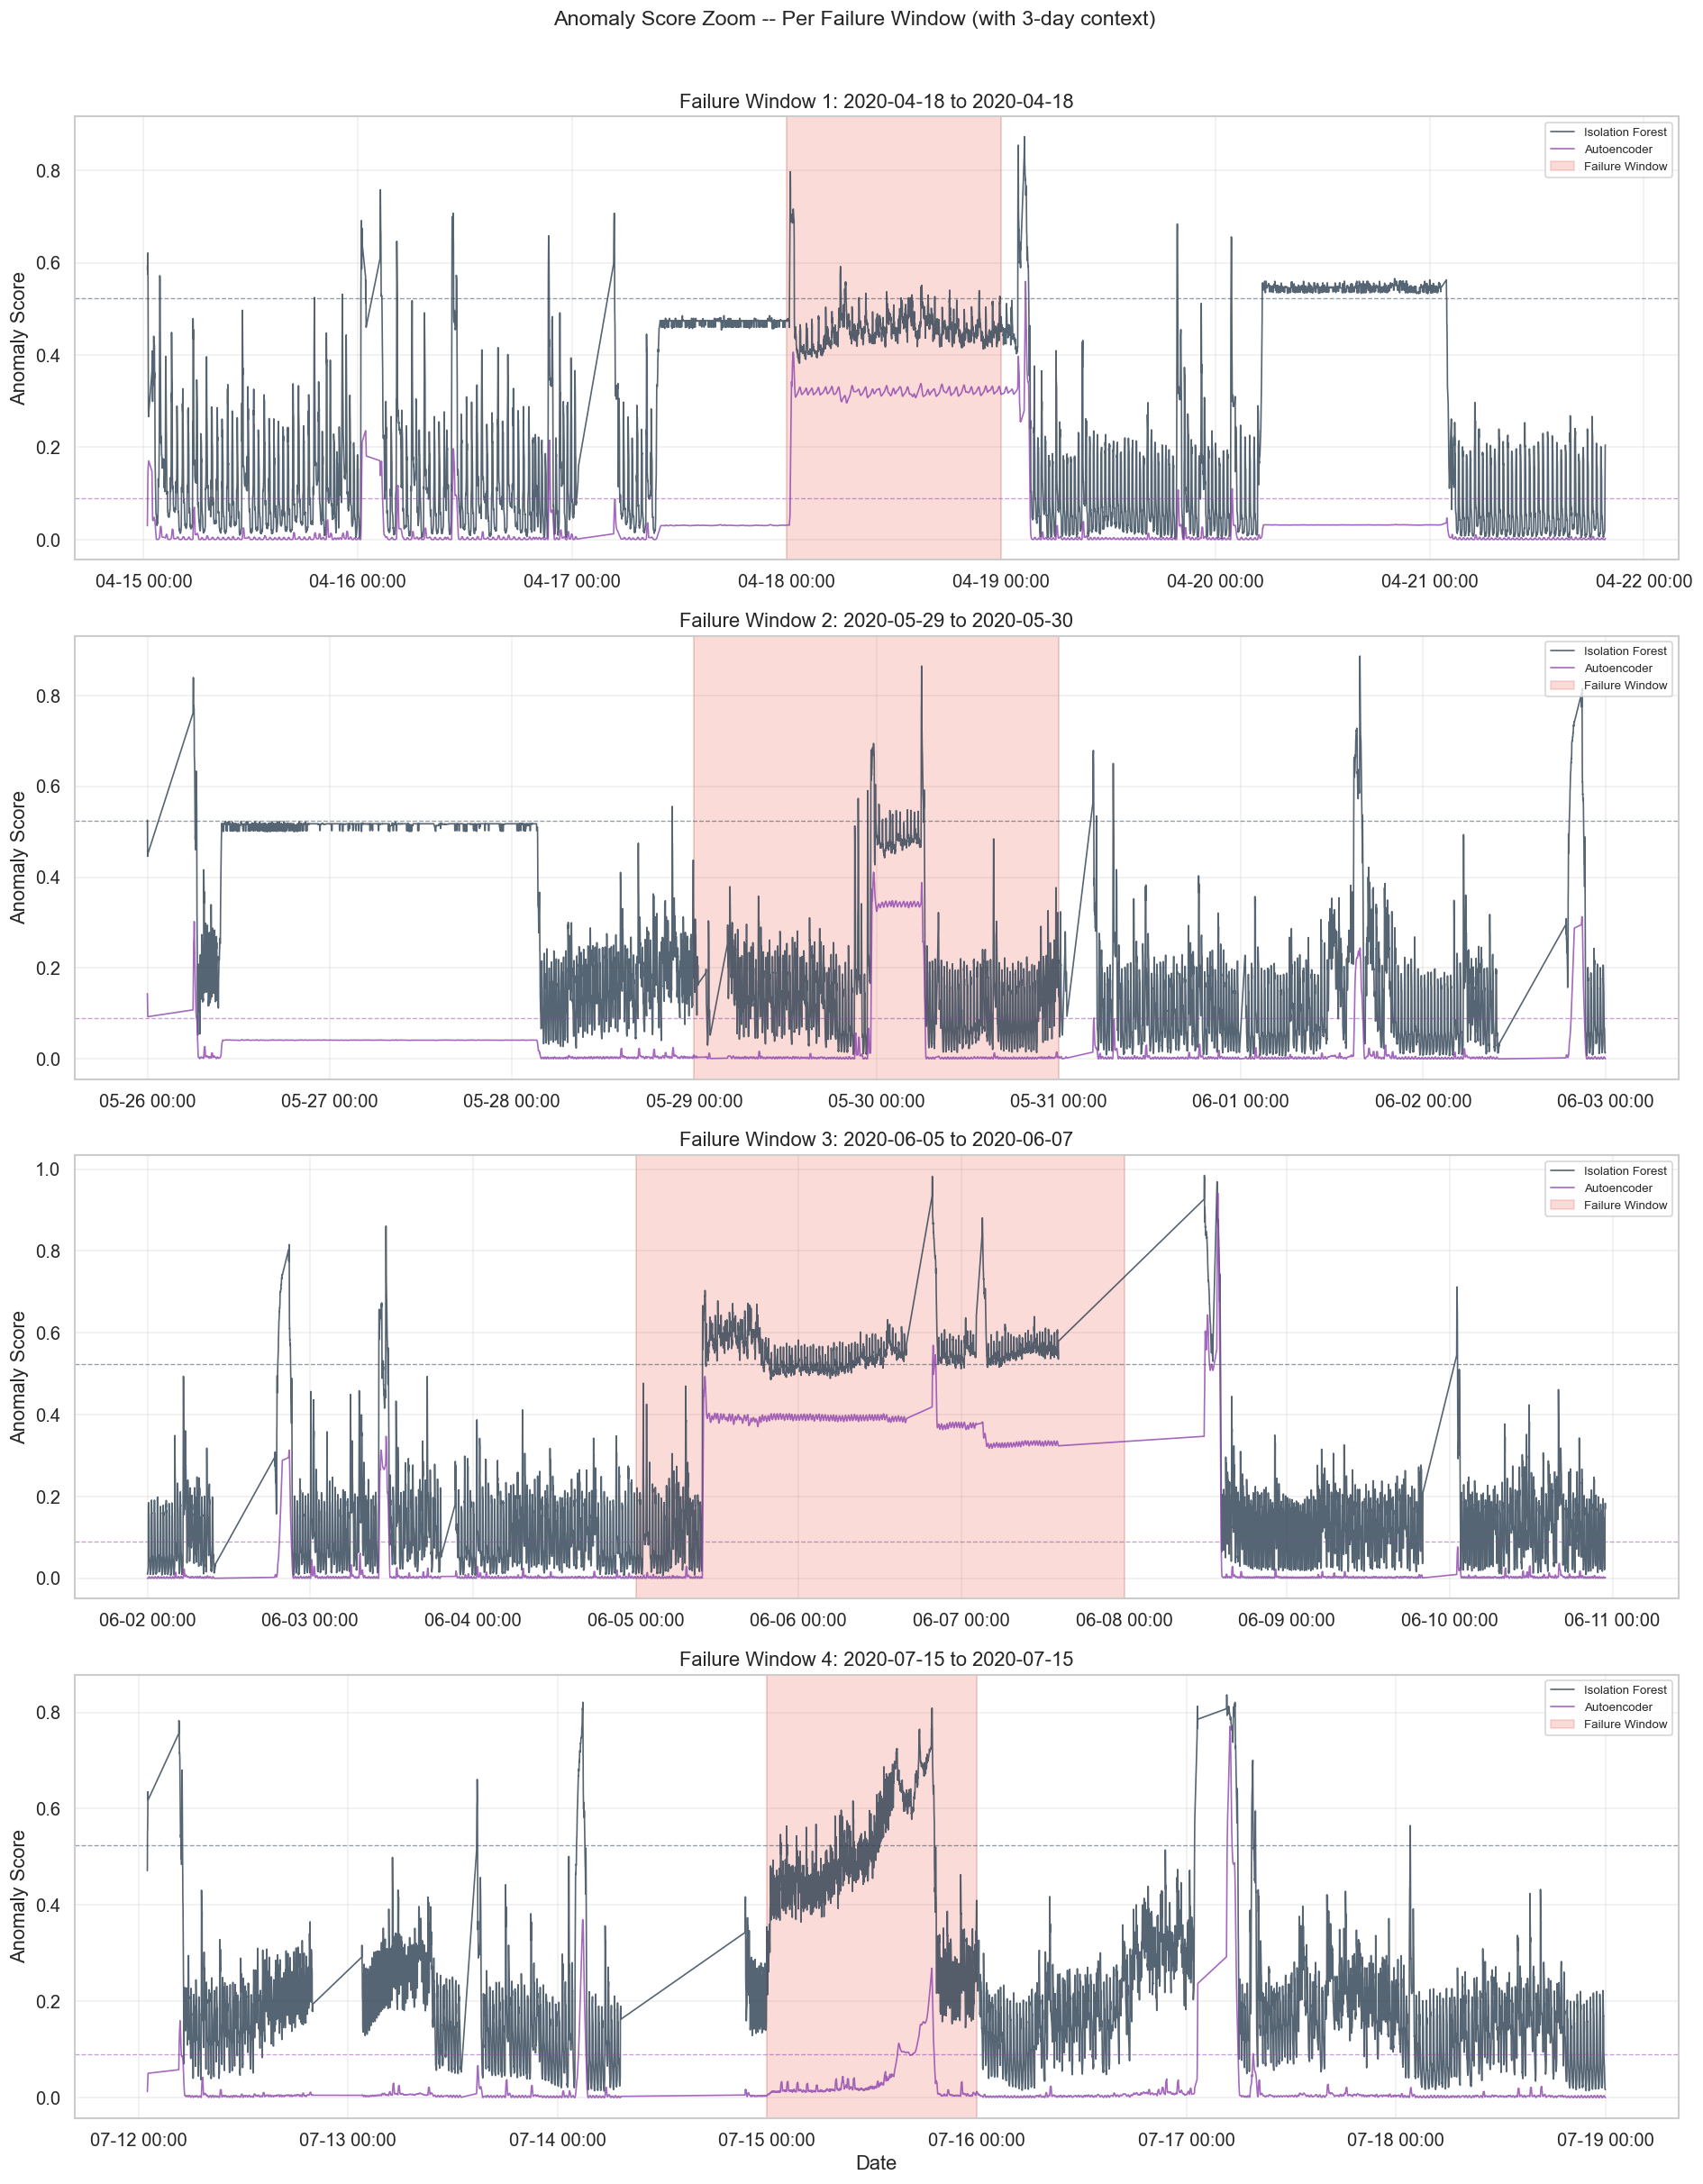

In [17]:
# Detailed zoom plots for each failure window
fig, axes = plt.subplots(4, 1, figsize=(16, 20))

for idx, ((start, end), ax) in enumerate(zip(FAILURE_WINDOWS_DT, axes)):
    # Expand window for context: 3 days before and after
    context_start = start - timedelta(days=3)
    context_end = end + timedelta(days=3)
    mask_context = (df_1min.index >= context_start) & (df_1min.index <= context_end)
    
    window_data = df_1min.loc[mask_context]
    
    if len(window_data) == 0:
        ax.text(0.5, 0.5, f"No data for window {idx+1}", ha="center", va="center")
        continue
    
    # Plot both scores
    ax.plot(window_data.index, window_data["iso_score"], linewidth=1,
            color="#2c3e50", alpha=0.8, label="Isolation Forest")
    ax.plot(window_data.index, window_data["ae_score"], linewidth=1,
            color="#8e44ad", alpha=0.8, label="Autoencoder")
    
    # Highlight the actual failure window
    ax.axvspan(start, end, color="#e74c3c", alpha=0.2, label="Failure Window")
    
    # Threshold lines
    ax.axhline(y=threshold_iso, color="#2c3e50", linestyle="--", linewidth=0.8, alpha=0.5)
    ax.axhline(y=threshold_ae, color="#8e44ad", linestyle="--", linewidth=0.8, alpha=0.5)
    
    ax.set_title(f"Failure Window {idx+1}: {start.date()} to {end.date()}")
    ax.set_ylabel("Anomaly Score")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M"))

axes[-1].set_xlabel("Date")
plt.suptitle("Anomaly Score Zoom -- Per Failure Window (with 3-day context)", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("models/a3_failure_window_zoom.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Ensemble Anomaly Score

Combine both models into a single ensemble score using a simple average.
This often improves detection robustness by compensating for individual model blind spots.

In [18]:
# Ensemble: simple average of normalized scores
df_1min["ensemble_score"] = (df_1min["iso_score"] + df_1min["ae_score"]) / 2

# Evaluate ensemble
ensemble_scores = df_1min["ensemble_score"].values
print("Ensemble Performance at Various Thresholds:")
print(f"{'Percentile':>10s} {'Prec':>8s} {'Rec':>8s} {'F1':>8s}")
print("-" * 40)

best_f1_ens = 0
best_pct_ens = 95

for pct in percentiles:
    p, r, f1_val, _ = evaluate_anomaly_detector(ensemble_scores, y_true, pct)
    if f1_val > best_f1_ens:
        best_f1_ens = f1_val
        best_pct_ens = pct
    print(f"{pct:>10d} {p:>8.3f} {r:>8.3f} {f1_val:>8.3f}")

print(f"\nBest ensemble threshold: {best_pct_ens}th percentile (F1={best_f1_ens:.3f})")

Ensemble Performance at Various Thresholds:
Percentile     Prec      Rec       F1
----------------------------------------
        90    0.229    0.644    0.338
        92    0.262    0.588    0.362
        94    0.334    0.566    0.420
        95    0.334    0.566    0.420
        96    0.493    0.554    0.522


        97    0.516    0.435    0.472
        98    0.421    0.237    0.303
        99    0.285    0.080    0.125

Best ensemble threshold: 96th percentile (F1=0.522)


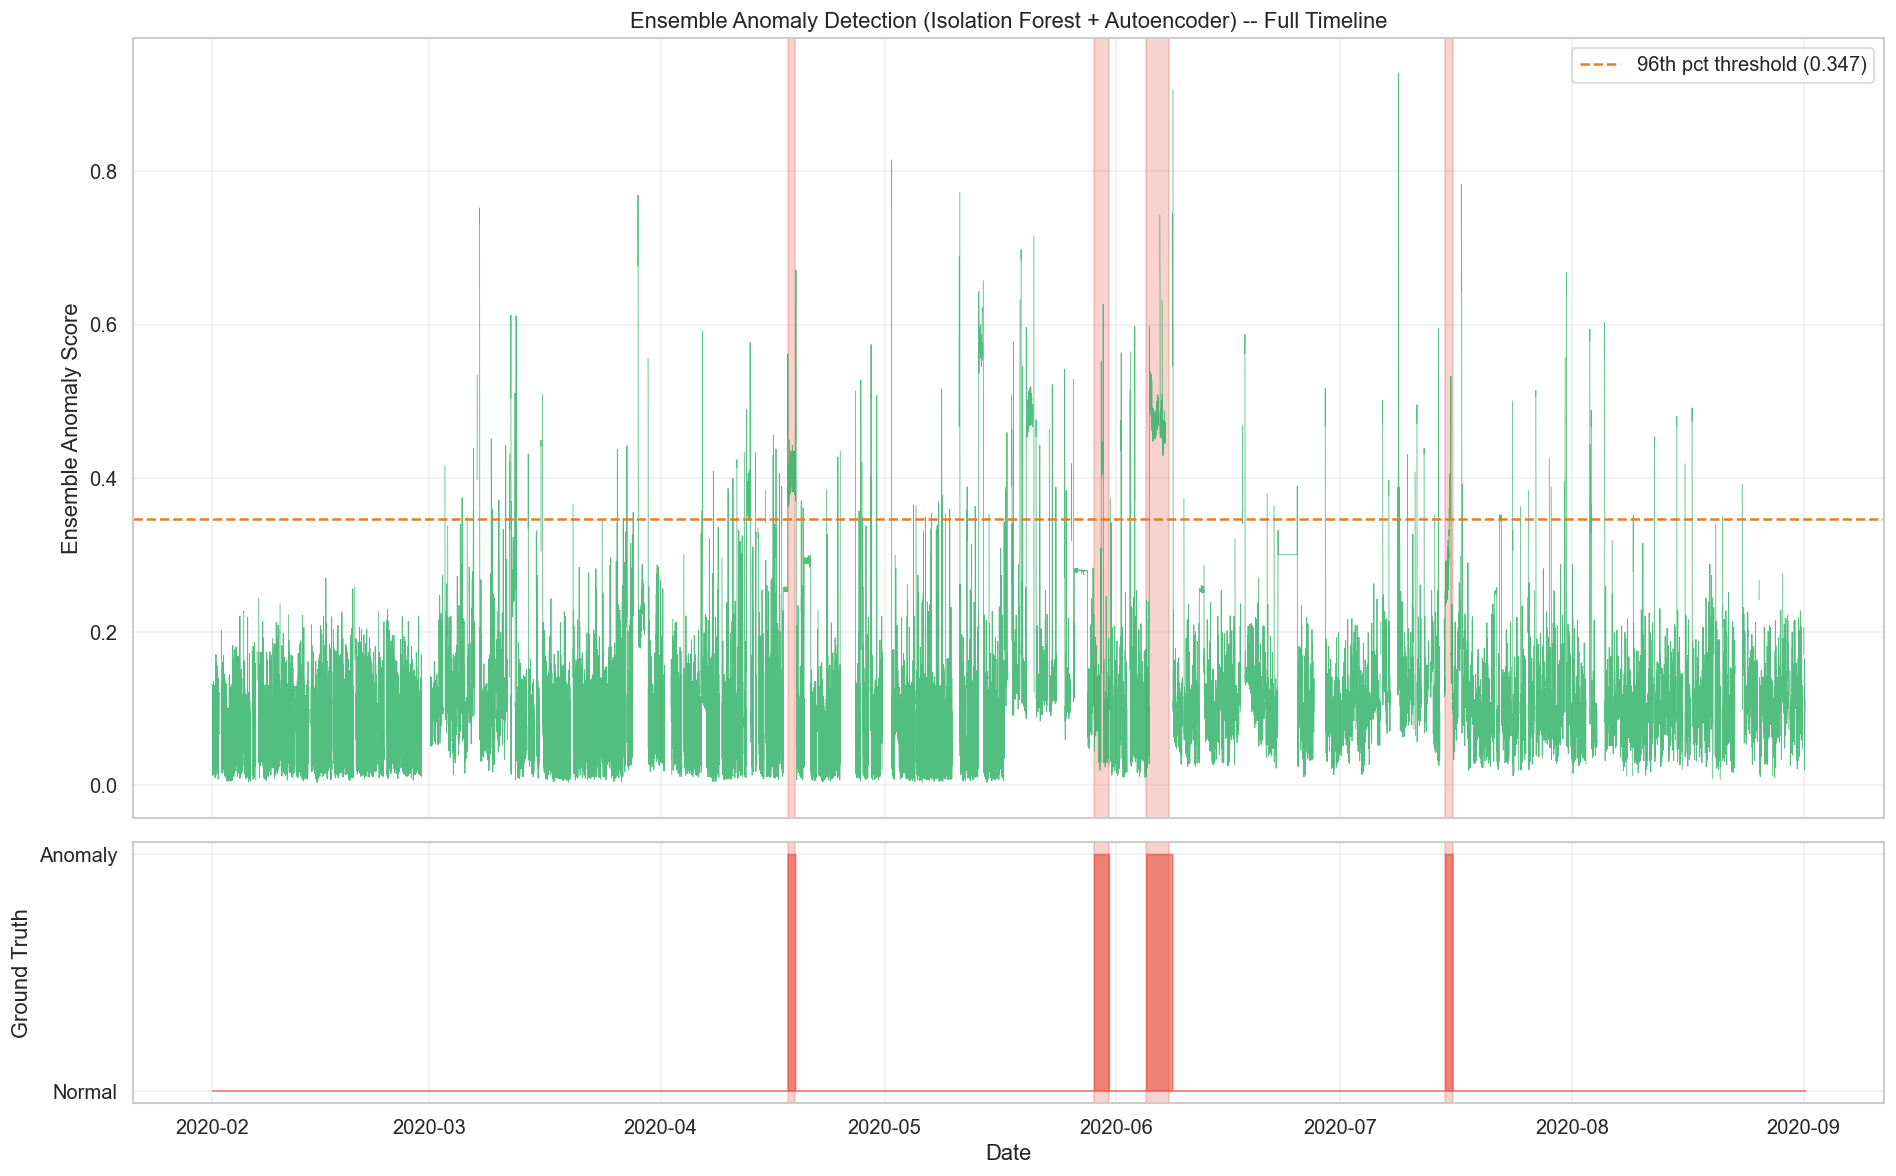

In [19]:
# Final ensemble timeline plot
fig, axes = plt.subplots(2, 1, figsize=(16, 10), sharex=True,
                         gridspec_kw={"height_ratios": [3, 1]})

plot_scores = df_1min["ensemble_score"].resample("10min").max()
axes[0].plot(plot_scores.index, plot_scores.values, linewidth=0.5, color="#27ae60", alpha=0.8)
axes[0].set_ylabel("Ensemble Anomaly Score")
axes[0].set_title("Ensemble Anomaly Detection (Isolation Forest + Autoencoder) -- Full Timeline")

ens_threshold = np.percentile(ensemble_scores, best_pct_ens)
axes[0].axhline(y=ens_threshold, color="#e67e22", linestyle="--", linewidth=1.5,
                label=f"{best_pct_ens}th pct threshold ({ens_threshold:.3f})")

for start, end in FAILURE_WINDOWS_DT:
    axes[0].axvspan(start, end, color="#e74c3c", alpha=0.25)
    axes[1].axvspan(start, end, color="#e74c3c", alpha=0.25)

axes[0].legend(loc="upper right")
axes[0].grid(True, alpha=0.3)

axes[1].fill_between(df_1min.index, 0, df_1min["is_anomaly"],
                      color="#e74c3c", alpha=0.6, step="post")
axes[1].set_ylabel("Ground Truth")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["Normal", "Anomaly"])
axes[1].set_xlabel("Date")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("models/a3_ensemble_timeline.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Remaining Useful Life (RUL) Estimation

For each failure window, examine the anomaly score trend in the days leading up to
the event. A rising trend before the failure suggests the anomaly score can serve
as a degradation indicator for RUL estimation.

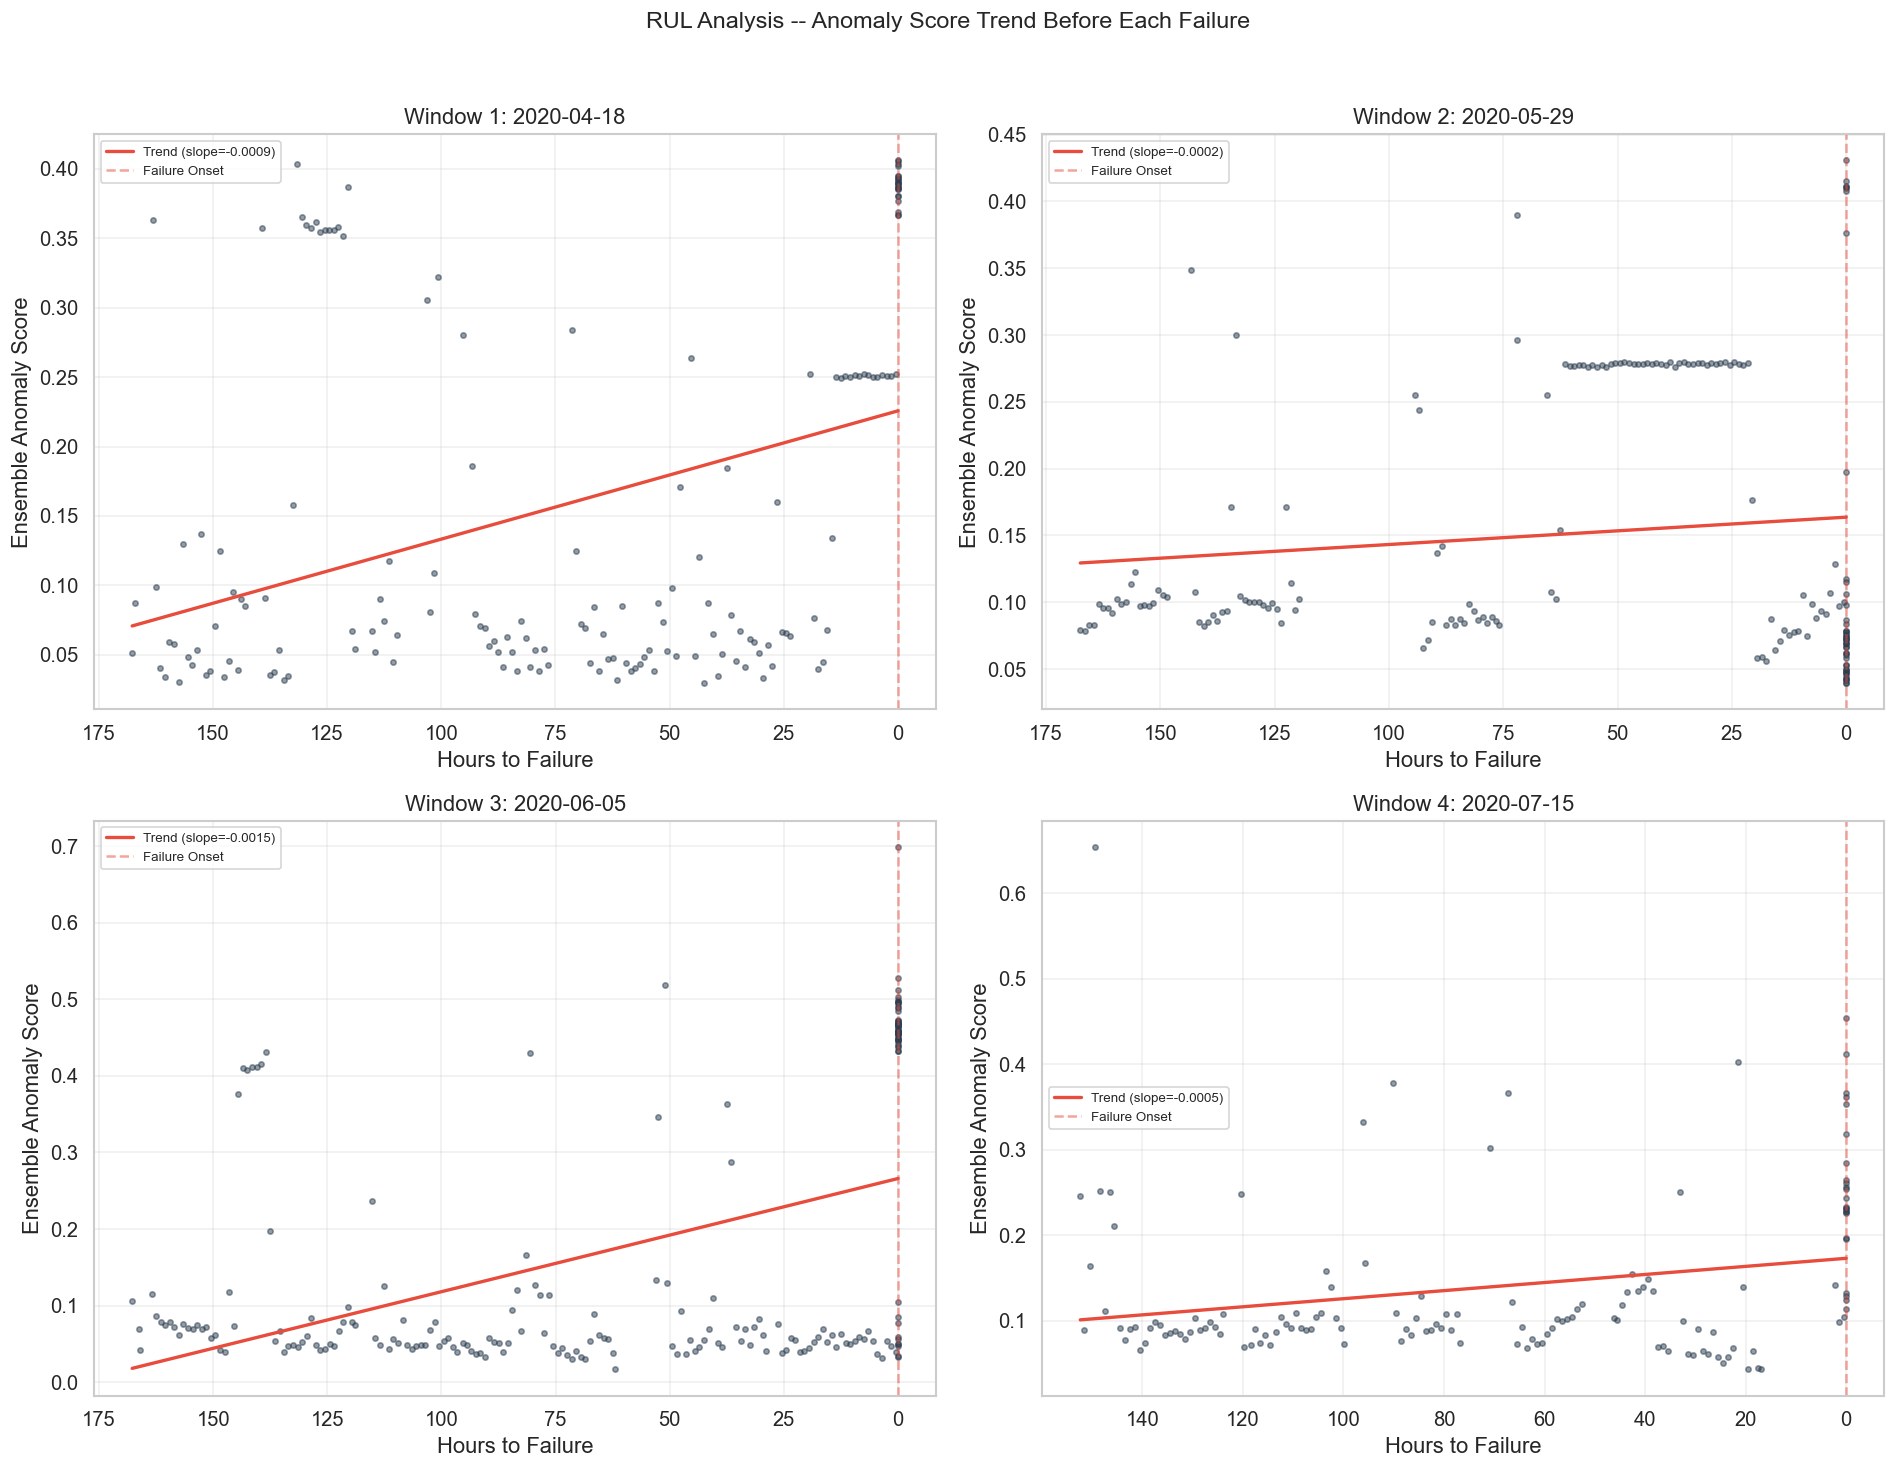


RUL Trend Summary:
  Window 1: slope=-0.000924 -- RISING (degradation detected)
  Window 2: slope=-0.000205 -- RISING (degradation detected)
  Window 3: slope=-0.001478 -- RISING (degradation detected)
  Window 4: slope=-0.000472 -- RISING (degradation detected)


In [20]:
# Analyze the trend leading up to each failure
LEAD_DAYS = 7  # Look back 7 days before each failure

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

rul_data = []

for idx, ((start, end), ax) in enumerate(zip(FAILURE_WINDOWS_DT, axes.flat)):
    lead_start = start - timedelta(days=LEAD_DAYS)
    mask_lead = (df_1min.index >= lead_start) & (df_1min.index <= end)
    
    lead_data = df_1min.loc[mask_lead].copy()
    
    if len(lead_data) == 0:
        ax.text(0.5, 0.5, f"No data for window {idx+1}", ha="center", va="center")
        continue
    
    # Compute time-to-failure in hours
    lead_data["hours_to_failure"] = (start - lead_data.index).total_seconds() / 3600
    lead_data.loc[lead_data.index >= start, "hours_to_failure"] = 0
    
    # Daily average ensemble score
    daily = lead_data[["ensemble_score", "hours_to_failure"]].resample("1h").mean()
    
    ax.scatter(daily["hours_to_failure"], daily["ensemble_score"],
               alpha=0.5, s=10, color="#2c3e50")
    
    # Fit a simple trend line
    valid = daily.dropna()
    if len(valid) > 2:
        z = np.polyfit(valid["hours_to_failure"], valid["ensemble_score"], 1)
        trend_x = np.linspace(valid["hours_to_failure"].max(), 0, 100)
        trend_y = np.polyval(z, trend_x)
        ax.plot(trend_x, trend_y, color="#e74c3c", linewidth=2,
                label=f"Trend (slope={z[0]:.4f})")
        rul_data.append({"window": idx+1, "slope": z[0], "intercept": z[1]})
    
    ax.axvline(x=0, color="#e74c3c", linestyle="--", alpha=0.5, label="Failure Onset")
    ax.set_xlabel("Hours to Failure")
    ax.set_ylabel("Ensemble Anomaly Score")
    ax.set_title(f"Window {idx+1}: {start.date()}")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.invert_xaxis()

plt.suptitle("RUL Analysis -- Anomaly Score Trend Before Each Failure", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("models/a3_rul_analysis.png", dpi=150, bbox_inches="tight")
plt.show()

if rul_data:
    print("\nRUL Trend Summary:")
    for rd in rul_data:
        direction = "RISING (degradation detected)" if rd["slope"] < 0 else "FLAT/FALLING"
        print(f"  Window {rd['window']}: slope={rd['slope']:.6f} -- {direction}")

## 13. Model Export

In [21]:
# Save Isolation Forest
joblib.dump({
    "model": iso_forest,
    "scaler": scaler,
    "feature_columns": feature_cols,
    "threshold_97pct": float(threshold_iso),
    "training_period": (HEALTHY_START, HEALTHY_END),
}, MODEL_DIR / "a3_isolation_forest.joblib")

# Save Autoencoder using torch.save
torch.save({
    "model_state_dict": autoencoder.state_dict(),
    "scaler": scaler,
    "feature_columns": feature_cols,
    "threshold_97pct": float(threshold_ae),
    "training_period": (HEALTHY_START, HEALTHY_END),
    "seq_len": SEQ_LEN,
}, MODEL_DIR / "a3_autoencoder.pth")

# Save ensemble configuration
joblib.dump({
    "ensemble_method": "mean",
    "models": ["a3_isolation_forest.joblib", "a3_autoencoder.pth"],
    "best_threshold_percentile": best_pct_ens,
    "best_threshold_value": float(ens_threshold),
}, MODEL_DIR / "a3_ensemble_config.joblib")

print(f"Models saved to {MODEL_DIR.resolve()}")
for f in sorted(MODEL_DIR.glob("a3_*.joblib")):
    print(f"  {f.name} ({f.stat().st_size / 1024:.1f} KB)")

Models saved to C:\Users\MSI\Documents\jesa\notebooks\models
  a3_autoencoder.joblib (94.8 KB)
  a3_ensemble_config.joblib (0.2 KB)
  a3_isolation_forest.joblib (23320.4 KB)


## 14. Verification Summary

In [22]:
print("=" * 60)
print("A3 ANOMALY DETECTION -- VERIFICATION SUMMARY")
print("=" * 60)
print()

# Check per-window detection at 97th percentile
windows_detected_iso = 0
windows_detected_ae = 0
windows_detected_ens = 0

for i, (start, end) in enumerate(FAILURE_WINDOWS_DT, 1):
    mask_window = (df_1min.index >= start) & (df_1min.index <= end)
    n = mask_window.sum()
    
    if n == 0:
        print(f"Window {i}: No data")
        continue
    
    iso_det = (df_1min.loc[mask_window, "iso_score"] >= threshold_iso).any()
    ae_det = (df_1min.loc[mask_window, "ae_score"] >= threshold_ae).any()
    ens_det = (df_1min.loc[mask_window, "ensemble_score"] >= ens_threshold).any()
    
    if iso_det:
        windows_detected_iso += 1
    if ae_det:
        windows_detected_ae += 1
    if ens_det:
        windows_detected_ens += 1
    
    print(f"Window {i} ({start.date()}): ISO={'DETECTED' if iso_det else 'MISSED':8s}  "
          f"AE={'DETECTED' if ae_det else 'MISSED':8s}  "
          f"ENS={'DETECTED' if ens_det else 'MISSED':8s}")

print()
print(f"Detection Summary (97th percentile threshold):")
print(f"  Isolation Forest: {windows_detected_iso}/4 windows detected")
print(f"  Autoencoder:      {windows_detected_ae}/4 windows detected")
print(f"  Ensemble:         {windows_detected_ens}/4 windows detected")
print()

target_met = windows_detected_ens >= 3
print(f"Target (>=3 of 4 windows): {'PASS' if target_met else 'BELOW TARGET'}")
print()

model_files = list(MODEL_DIR.glob("a3_*.joblib"))
print(f"Model artifacts: {len(model_files)} files saved")
for f in sorted(model_files):
    print(f"  {f.name}")
print()
print("Notebook execution: COMPLETE")

A3 ANOMALY DETECTION -- VERIFICATION SUMMARY

Window 1 (2020-04-18): ISO=DETECTED  AE=DETECTED  ENS=DETECTED
Window 2 (2020-05-29): ISO=DETECTED  AE=DETECTED  ENS=DETECTED
Window 3 (2020-06-05): ISO=DETECTED  AE=DETECTED  ENS=DETECTED
Window 4 (2020-07-15): ISO=DETECTED  AE=DETECTED  ENS=DETECTED

Detection Summary (97th percentile threshold):
  Isolation Forest: 4/4 windows detected
  Autoencoder:      4/4 windows detected
  Ensemble:         4/4 windows detected

Target (>=3 of 4 windows): PASS

Model artifacts: 3 files saved
  a3_autoencoder.joblib
  a3_ensemble_config.joblib
  a3_isolation_forest.joblib

Notebook execution: COMPLETE
